In [1]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [2]:
# try running the following code, if you see errors on Windows OS

import os
os.environ['KMP_DUPLICATE_LIB_OK']='TRUE'

In [3]:
transform=transforms.Compose([
      transforms.ToTensor(),
      transforms.Normalize((0.2860,), (0.3530,))
  ])

training_data = torchvision.datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform,
)

test_data = torchvision.datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform,
)

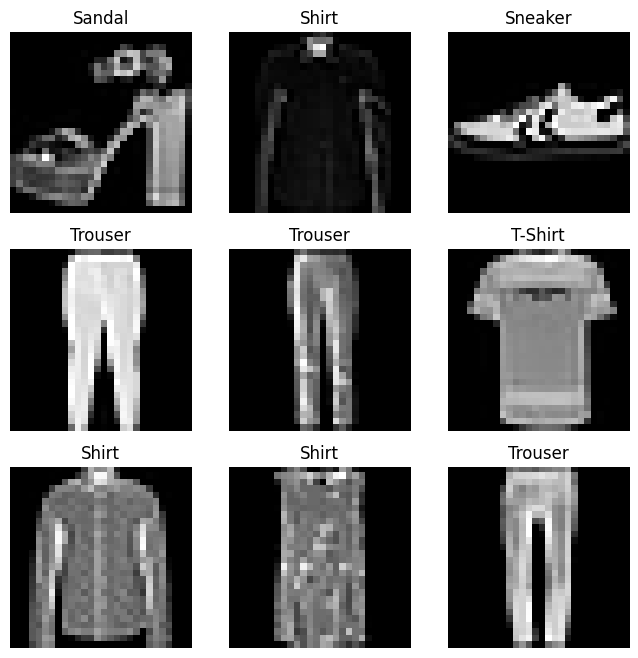

In [4]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

In [5]:
# Find your own hyper-parameters 

num_epochs = 50
batch_size = 128
weight_decay = 1e-4
learning_rate = 0.001

In [6]:
# Create data loaders.
train_dataloader = torch.utils.data.DataLoader(training_data, batch_size=batch_size)
test_dataloader = torch.utils.data.DataLoader(test_data, batch_size=batch_size)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([128, 1, 28, 28])
Shape of y: torch.Size([128]) torch.int64


In [7]:
# Get cpu or gpu device for training.
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

# class NeuralNet(nn.Module):
#     def __init__(self,num_classes=10,img_size=32, patch_size=4, embed_dim=64):
#         super(NeuralNet, self).__init__()
#         self.cnn_branch = nn.Sequential(
#             nn.Conv2d(1, 16, kernel_size=3, padding=1),
#             nn.BatchNorm2d(16),
#             nn.ReLU(),
#             nn.MaxPool2d(2), # 14x14
#             nn.Conv2d(16, 32, kernel_size=3, padding=1),
#             nn.BatchNorm2d(32),
#             nn.ReLU(),
#             nn.MaxPool2d(2), # 7x7
#             nn.Flatten()     # 输出: 32*7*7 = 1568
#         )
#
#         # Transformer 分支：处理全局信息
#         self.embed_dim = 32
#         self.patch_size = 4
#         self.num_patches = (28 // self.patch_size) ** 2 # 49个 patches
#
#         self.patch_embed = nn.Conv2d(1, self.embed_dim, kernel_size=self.patch_size, stride=self.patch_size)
#         # 修正了之前的警告，添加了 batch_first=True
#         encoder_layer = nn.TransformerEncoderLayer(d_model=self.embed_dim, nhead=4, batch_first=True)
#         self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
#
#         # 融合与分类
#         self.fc_input_dim = 1568 + (self.num_patches * self.embed_dim)
#         self.classifier = nn.Sequential(
#             nn.Dropout(0.3),
#             nn.Linear(self.fc_input_dim, num_classes)
#   )
#
#     def forward(self, x):
#         # 分支 1: CNN
#         cnn_out = self.cnn_branch(x)
#
#         # Transformer 分支
#         x_patch = self.patch_embed(x)             # [B, 32, 7, 7]
#         x_patch = x_patch.flatten(2).transpose(1, 2) # [B, 49, 32]
#         trans_out = self.transformer(x_patch).flatten(1) # [B, 1568]
#
#         # 拼接融合
#         out = torch.cat((cnn_out, trans_out), dim=1)
#         return self.classifier(out)

class NeuralNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
              nn.Conv2d(1, 32, 3, padding=1),
              nn.BatchNorm2d(32),
              nn.ReLU(),
              nn.Conv2d(32, 32, 3, padding=1),
              nn.BatchNorm2d(32),
              nn.ReLU(),
              nn.MaxPool2d(2),

              nn.Conv2d(32, 64, 3, padding=1),
              nn.BatchNorm2d(64),
              nn.ReLU(),
              nn.Conv2d(64, 64, 3, padding=1),
              nn.BatchNorm2d(64),
              nn.ReLU(),
              nn.MaxPool2d(2),

              nn.Conv2d(64, 128, 3, padding=1),
              nn.BatchNorm2d(128),
              nn.ReLU(),
              nn.AdaptiveAvgPool2d((1, 1)),
              nn.Flatten()
          )

        self.classifier = nn.Sequential(
              nn.Dropout(0.4),
              nn.Linear(128, num_classes)
          )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = NeuralNet().to(device)

Using cuda device


In [8]:
# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay = weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
      optimizer, T_max=num_epochs
  )

In [9]:
# Train the model
total_step = len(train_dataloader)
for epoch in range(num_epochs):
    model.train()
    for i, (images, labels) in enumerate(train_dataloader):
        images = images.to(device)
        labels = labels.to(device)
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        if (i+1) % 100 == 0:
            print ('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}' 
                   .format(epoch+1, num_epochs, i+1, total_step, loss.item()))

    scheduler.step()


Epoch [1/50], Step [100/469], Loss: 0.7487
Epoch [1/50], Step [200/469], Loss: 0.5810
Epoch [1/50], Step [300/469], Loss: 0.3708
Epoch [1/50], Step [400/469], Loss: 0.3824
Epoch [2/50], Step [100/469], Loss: 0.4374
Epoch [2/50], Step [200/469], Loss: 0.4013
Epoch [2/50], Step [300/469], Loss: 0.2322
Epoch [2/50], Step [400/469], Loss: 0.2965
Epoch [3/50], Step [100/469], Loss: 0.3221
Epoch [3/50], Step [200/469], Loss: 0.2902
Epoch [3/50], Step [300/469], Loss: 0.2066
Epoch [3/50], Step [400/469], Loss: 0.2487
Epoch [4/50], Step [100/469], Loss: 0.3036
Epoch [4/50], Step [200/469], Loss: 0.2733
Epoch [4/50], Step [300/469], Loss: 0.1974
Epoch [4/50], Step [400/469], Loss: 0.2348
Epoch [5/50], Step [100/469], Loss: 0.2668
Epoch [5/50], Step [200/469], Loss: 0.2677
Epoch [5/50], Step [300/469], Loss: 0.1464
Epoch [5/50], Step [400/469], Loss: 0.1865
Epoch [6/50], Step [100/469], Loss: 0.2458
Epoch [6/50], Step [200/469], Loss: 0.2717
Epoch [6/50], Step [300/469], Loss: 0.1417
Epoch [6/50

In [10]:
# Test the model
model.eval()  # eval mode (batchnorm uses moving mean/variance instead of mini-batch mean/variance)
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_dataloader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print('Test Accuracy of the model on the 10000 test images: {} %'.format(100 * correct / total))

Test Accuracy of the model on the 10000 test images: 92.81 %
